# Seminar 1 · Part 3: The Iris flowers

We build a **Gaussian naive Bayes classifier from scratch**: it reads 4 measurements of an iris flower and tells its species.

**Plan of this notebook**

1. Load the data
2. Look at the data (EDA)
3. Build the classifier from scratch
4. Train it
5. Use it
6. Evaluate it

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris     # the Iris dataset comes with scikit-learn

SEED = 0                                   # fixed random seed: everyone gets the same split and the same numbers
SPECIES = ["setosa", "versicolor", "virginica"]
FEATURES = ["sepal length", "sepal width", "petal length", "petal width"]   # all in cm
COLORS = {"setosa": "#2e9e6b", "versicolor": "#2a78d6", "virginica": "#8e4fc0"}   # the slide colours

## 1. Load the data

**The Iris dataset**, first used by R. A. Fisher (1936). 150 flowers, 50 of each species, and 4 measurements of each flower in cm.

We number the flowers **1 to 150**, as on the slides. (Python itself counts from 0: in a plain array, flower 51 is row 50. To avoid this trap, our table uses the numbers 1 to 150 as its index.)

In [2]:
iris = load_iris()
data = pd.DataFrame(iris.data, columns=FEATURES)
data["species"] = [SPECIES[k] for k in iris.target]   # iris.target holds 0, 1, 2
data.index = range(1, len(data) + 1)                  # flower numbers 1, 2, ..., 150

print("Flowers:", len(data))
data.loc[[1, 51, 101]]                                # one flower of each species

Flowers: 150


,sepal length,sepal width,petal length,petal width,species
1,5.1,3.5,1.4,0.2,setosa
51,7.0,3.2,4.7,1.4,versicolor
101,6.3,3.3,6.0,2.5,virginica


## 2. Look at the data (EDA)

### How many flowers of each species?

In [3]:
print(data["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### The mean of each feature, by species

In [4]:
data.groupby("species")[FEATURES].mean().round(2)

,sepal length,sepal width,petal length,petal width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


### One histogram per feature

Each species has its own colour. The histograms are drawn as densities (`density=True`): the total area of each species' bars is 1, like the area under a PDF.

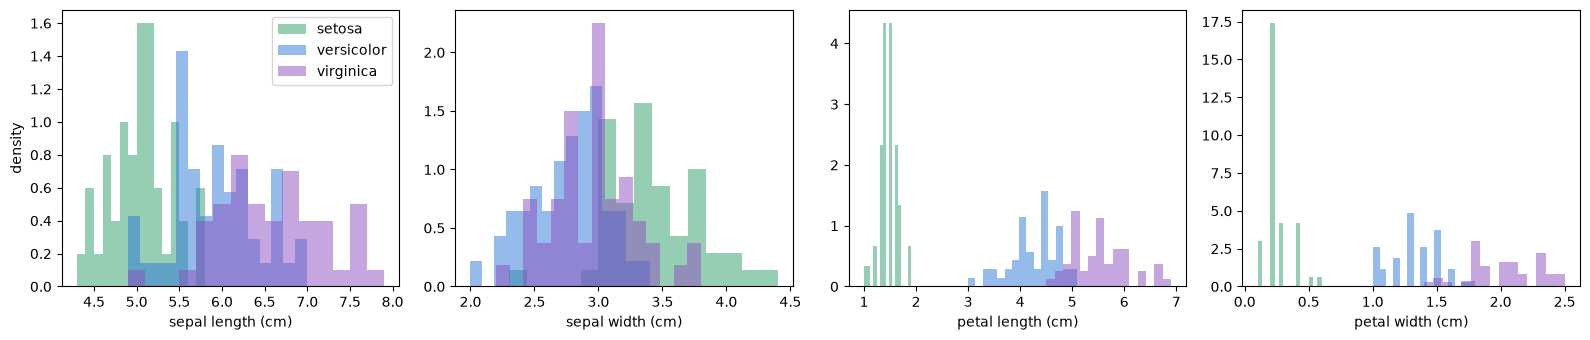

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, feature in zip(axes, FEATURES):
    for c in SPECIES:
        ax.hist(data.loc[data["species"] == c, feature], bins=15, density=True, alpha=0.5, color=COLORS[c], label=c)
    ax.set_xlabel(feature + " (cm)")
axes[0].set_ylabel("density")
axes[0].legend()
plt.tight_layout()
plt.show()

### Petal length against petal width

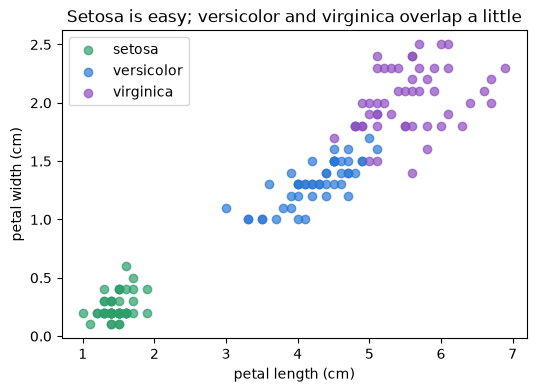

In [6]:
plt.figure(figsize=(6, 4))
for c in SPECIES:
    part = data[data["species"] == c]
    plt.scatter(part["petal length"], part["petal width"], color=COLORS[c], label=c, alpha=0.7)
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.legend()
plt.title("Setosa is easy; versicolor and virginica overlap a little")
plt.show()

### Are the features independent? Correlation matrices

The naive Bayes assumption says: **given the species**, the 4 features are independent. If two random variables are independent, their correlation is 0 (Carlos, Part 1 notes, p. 9). So a correlation far from 0 shows that they are **not** independent.

`DataFrame.corr()` computes the **sample correlation coefficient** of every pair of features (ps4ds, Definition 8.10).

**Trap question.** Over all 150 flowers, petal length and petal width have correlation 0.96. Does this break the naive Bayes assumption?

In [7]:
print("All 150 flowers:")
print(data[FEATURES].corr().round(2))

All 150 flowers:
              sepal length  sepal width  petal length  petal width
sepal length          1.00        -0.12          0.87         0.82
sepal width          -0.12         1.00         -0.43        -0.37
petal length          0.87        -0.43          1.00         0.96
petal width           0.82        -0.37          0.96         1.00


Not by itself: the assumption is about **one species at a time**. So we must look inside each species.

In [8]:
for c in SPECIES:
    print(f"Only {c}:")
    print(data.loc[data["species"] == c, FEATURES].corr().round(2))
    print()

Only setosa:
              sepal length  sepal width  petal length  petal width
sepal length          1.00         0.74          0.27         0.28
sepal width           0.74         1.00          0.18         0.23
petal length          0.27         0.18          1.00         0.33
petal width           0.28         0.23          0.33         1.00

Only versicolor:
              sepal length  sepal width  petal length  petal width
sepal length          1.00         0.53          0.75         0.55
sepal width           0.53         1.00          0.56         0.66
petal length          0.75         0.56          1.00         0.79
petal width           0.55         0.66          0.79         1.00

Only virginica:
              sepal length  sepal width  petal length  petal width
sepal length          1.00         0.46          0.86         0.28
sepal width           0.46         1.00          0.40         0.54
petal length          0.86         0.40          1.00         0.32
petal width   

Inside virginica, sepal length and petal length have correlation 0.86. The naive Bayes assumption is **false**. Let's build the classifier anyway, and see how well it works.

## 3. Build the classifier from scratch

### The model, in one line

Given the species $\eta = c$, each feature $\zeta_\ell$ has the normal distribution $\mathcal{N}(a_{c,\ell}, \sigma^2_{c,\ell})$, and the 4 features are conditionally independent (the naive Bayes assumption). The predicted species of a flower with measurements $z = (z_1, z_2, z_3, z_4)$ is

$$\hat{c} = \operatorname*{argmax}_{c} \Big[\log \hat{P}(\eta = c) + \sum_{\ell=1}^{4} \log \hat{f}_{\zeta_\ell \mid \eta}(z_\ell \mid c)\Big],$$

where $\hat{f}_{\zeta_\ell \mid \eta}(\cdot \mid c)$ is the PDF of $\mathcal{N}(\hat{a}_{c,\ell}, \hat{\sigma}^2_{c,\ell})$:

$$\log \hat{f}_{\zeta_\ell \mid \eta}(t \mid c) = -\frac{1}{2}\log\big(2\pi\hat{\sigma}^2_{c,\ell}\big) - \frac{(t - \hat{a}_{c,\ell})^2}{2\hat{\sigma}^2_{c,\ell}}.$$

**Training** computes the estimates from the training flowers:

$$\hat{P}(\eta = c) = \frac{m_c}{m}, \qquad \hat{a}_{c,\ell} = \frac{1}{m_c} \sum_{\text{class } c} z_\ell, \qquad \hat{\sigma}^2_{c,\ell} = \frac{1}{m_c} \sum_{\text{class } c} (z_\ell - \hat{a}_{c,\ell})^2.$$

We divide by $m_c$, not by $m_c - 1$: these are the maximum-likelihood estimates (ps4ds, Theorem 3.35), and scikit-learn does the same (ISLP, p. 192).

In [9]:
def train_gaussian_nb(X, labels):
    '''Training = means and variances.
    X: one row per training flower, one column per feature.  labels: the species of each flower.
    Returns P^(eta = c), a^_{c,l} and sigma^2_{c,l}, for every species c (and every feature l).'''
    X, labels = np.asarray(X), np.asarray(labels)
    m = len(labels)                                            # number of training flowers
    prior, a_hat, var_hat = {}, {}, {}
    for c in SPECIES:
        X_c = X[labels == c]                                   # the m_c training flowers of class c
        m_c = len(X_c)
        prior[c] = m_c / m                                     # P^(eta = c) = m_c / m
        a_hat[c] = X_c.sum(axis=0) / m_c                       # a^_{c,l}: 4 means, one per feature
        var_hat[c] = ((X_c - a_hat[c]) ** 2).sum(axis=0) / m_c  # sigma^2_{c,l}: divide by m_c
    return prior, a_hat, var_hat


def log_normal_pdf(t, a, var):
    '''log of the PDF of N(a, var) at the point t.'''
    return -0.5 * np.log(2 * math.pi * var) - (t - a) ** 2 / (2 * var)


def log_scores(z, prior, a_hat, var_hat):
    '''For each species c: log P^(eta = c) + sum over l of log f^(z_l | c).'''
    z = np.asarray(z, dtype=float)
    return {c: math.log(prior[c]) + log_normal_pdf(z, a_hat[c], var_hat[c]).sum() for c in SPECIES}


def predict(z, prior, a_hat, var_hat):
    '''The predicted species c^: the species with the largest score (argmax).'''
    s = log_scores(z, prior, a_hat, var_hat)
    return max(s, key=s.get)


def posterior(z, prior, a_hat, var_hat):
    '''P^(eta = c | zeta = z) for every species c: Bayes' formula with a density.
    The posterior of c is exp(score_c) / (sum over c' of exp(score_c')).
    We first subtract the largest score from every score: the fraction does not change,
    and exp() never underflows to 0 / 0.'''
    s = log_scores(z, prior, a_hat, var_hat)
    top = max(s.values())
    weight = {c: math.exp(s[c] - top) for c in SPECIES}
    total = sum(weight.values())
    return {c: weight[c] / total for c in SPECIES}

### Check the code on flower 51, as on the slides

On the slides we trained on **all 150 flowers** and computed flower 51 by hand: versicolor with $\hat{P}(\eta = \text{versicolor} \mid \zeta = z) \approx 0.80$, virginica $\approx 0.20$. Our code should give the same numbers.

(The slide adds the numbers *after* rounding them to 2 decimals, so its sums can differ from the sums below in the last digit.)

In [10]:
model_all = train_gaussian_nb(data[FEATURES], data["species"])
prior, a_hat, var_hat = model_all

z = data.loc[51, FEATURES].to_numpy(dtype=float)     # flower 51: (7.0, 3.2, 4.7, 1.4)
table = pd.DataFrame(
    {c: [math.log(prior[c])] + list(log_normal_pdf(z, a_hat[c], var_hat[c])) for c in SPECIES},
    index=["log P^(eta = c)", "l = 1", "l = 2", "l = 3", "l = 4"]).T
table["sum"] = table.sum(axis=1)
print(table.round(2))
print()
for c, p in posterior(z, *model_all).items():
    print(f"P^(eta = {c:10} | zeta = z) = {p:.3f}")

            log P^(eta = c)  l = 1  l = 2   l = 3  l = 4     sum
setosa                 -1.1 -16.19  -0.12 -176.53 -59.84 -253.78
versicolor             -1.1  -2.42  -0.71   -0.60   0.64   -4.18
virginica              -1.1  -0.67  -0.03   -1.53  -2.27   -5.59

P^(eta = setosa     | zeta = z) = 0.000
P^(eta = versicolor | zeta = z) = 0.804
P^(eta = virginica  | zeta = z) = 0.196


### A density is not a probability

The trap question from the slides: setosa petal width (feature $\ell = 4$). The PDF at 0.25 cm is larger than 1, so it cannot be a probability. A probability is an **area** under the PDF. We compute areas with the CDF of the normal distribution, written with `math.erf`.

In [11]:
a, var = a_hat["setosa"][3], var_hat["setosa"][3]     # setosa, petal width (index 3 = feature 4)
print(f"a^ = {a:.3f} cm,  sigma^ = {math.sqrt(var):.3f} cm")
print(f"PDF at 0.25 cm: {math.exp(log_normal_pdf(0.25, a, var)):.2f}")


def normal_cdf(t, a, var):
    '''P(zeta <= t) for zeta ~ N(a, var).'''
    return 0.5 * (1 + math.erf((t - a) / math.sqrt(2 * var)))


print(f"P(0.24 <= zeta_4 <= 0.26 | setosa) = {normal_cdf(0.26, a, var) - normal_cdf(0.24, a, var):.3f}")
print(f"P(zeta_4 < 0 | setosa)             = {normal_cdf(0, a, var):.3f}   <- a negative petal width!")

a^ = 0.246 cm,  sigma^ = 0.104 cm
PDF at 0.25 cm: 3.82
P(0.24 <= zeta_4 <= 0.26 | setosa) = 0.076
P(zeta_4 < 0 | setosa)             = 0.009   <- a negative petal width!


The fitted normal distribution gives a **negative** petal width a small but positive probability. The normal model is only an approximation.

## 4. Train it

As for the spam filter: **80% training set**, **20% test set**, in a random order fixed by the seed. The test set stays hidden until step 6. The table keeps the flower numbers 1 to 150.

In [12]:
rng = np.random.default_rng(SEED)
order = rng.permutation(len(data))           # the flowers in a random order
n_train = int(0.8 * len(data))

train = data.iloc[order[:n_train]]
test = data.iloc[order[n_train:]]
print("Training set:", len(train), "flowers;  of each species:", dict(train["species"].value_counts()))
print("Test set:    ", len(test), "flowers;  of each species:", dict(test["species"].value_counts()))

Training set: 120 flowers;  of each species: {'setosa': np.int64(42), 'virginica': np.int64(40), 'versicolor': np.int64(38)}
Test set:     30 flowers;  of each species: {'versicolor': np.int64(12), 'virginica': np.int64(10), 'setosa': np.int64(8)}


In [13]:
model = train_gaussian_nb(train[FEATURES], train["species"])
prior_train, a_hat_train, var_hat_train = model

for c in SPECIES:
    print(f"P^(eta = {c}) = {prior_train[c]:.3f}")

P^(eta = setosa) = 0.350
P^(eta = versicolor) = 0.317
P^(eta = virginica) = 0.333


### What did it learn?

12 means and 12 standard deviations $\hat{\sigma}_{c,\ell} = \sqrt{\hat{\sigma}^2_{c,\ell}}$, in cm. Compare with the mean of each feature by species in step 2.

In [14]:
learned = pd.DataFrame(
    {c: [f"{a_hat_train[c][l]:.2f} ({math.sqrt(var_hat_train[c][l]):.2f})" for l in range(4)] for c in SPECIES},
    index=FEATURES).T
print("mean (standard deviation), trained on the training set:")
learned

mean (standard deviation), trained on the training set:


,sepal length,sepal width,petal length,petal width
setosa,4.97 (0.34),3.39 (0.35),1.46 (0.18),0.25 (0.11)
versicolor,5.91 (0.52),2.75 (0.33),4.24 (0.47),1.32 (0.19)
virginica,6.67 (0.64),2.97 (0.34),5.63 (0.55),2.01 (0.28)


## 5. Use it

The game round of the slides: flowers 1, 51, 78 and 120, with the model trained on all 150 flowers (as on the slides). Guess first, then run the cell.

In [15]:
for number in [1, 51, 78, 120]:
    z = data.loc[number, FEATURES].to_numpy(dtype=float)
    post = posterior(z, *model_all)
    says = max(post, key=post.get)
    mark = "" if says == data.loc[number, "species"] else "   <- wrong"
    print(f"flower {number:3}: {z}  true: {data.loc[number, 'species']:10}  the classifier says: {says:10} ({post[says]:.2f}){mark}")

flower   1: [5.1 3.5 1.4 0.2]  true: setosa      the classifier says: setosa     (1.00)
flower  51: [7.  3.2 4.7 1.4]  true: versicolor  the classifier says: versicolor (0.80)
flower  78: [6.7 3.  5.  1.7]  true: versicolor  the classifier says: virginica  (0.92)   <- wrong
flower 120: [6.  2.2 5.  1.5]  true: virginica   the classifier says: versicolor (0.96)   <- wrong


Which flowers does the model (trained on all 150) get wrong?

In [16]:
wrong = [number for number in data.index
         if predict(data.loc[number, FEATURES].to_numpy(dtype=float), *model_all) != data.loc[number, "species"]]
print("Wrong:", wrong, f"  ({len(data) - len(wrong)} of {len(data)} right)")

Wrong: [53, 71, 78, 107, 120, 134]   (144 of 150 right)


**Your turn.** Measure an imaginary flower: change the 4 numbers (sepal length, sepal width, petal length, petal width, in cm).

In [17]:
my_flower = [6.0, 3.0, 4.8, 1.6]
for c, p in posterior(my_flower, *model).items():
    print(f"P^(eta = {c:10} | zeta = z) = {p:.3f}")

P^(eta = setosa     | zeta = z) = 0.000
P^(eta = versicolor | zeta = z) = 0.801
P^(eta = virginica  | zeta = z) = 0.199


## 6. Evaluate it

Now the test set. The **confusion matrix** counts the test flowers by predicted species (rows) and by gold label (columns). With 3 species, it is $3 \times 3$. The correct answers are on the diagonal.

In [18]:
test = test.assign(predicted=[predict(z, *model) for z in test[FEATURES].to_numpy(dtype=float)])

confusion = pd.crosstab(test["predicted"], test["species"]).reindex(index=SPECIES, columns=SPECIES, fill_value=0)
confusion.index.name, confusion.columns.name = "predicted", "gold"
print(confusion)

accuracy = (test["predicted"] == test["species"]).mean()
print(f"\naccuracy = {accuracy:.3f}")
print("\nThe mistakes:")
print(test[test["predicted"] != test["species"]])

gold        setosa  versicolor  virginica
predicted                                
setosa           8           0          0
versicolor       0          11          0
virginica        0           1         10

accuracy = 0.967

The mistakes:
    sepal length  sepal width  petal length  petal width     species  \
78           6.7          3.0           5.0          1.7  versicolor   

    predicted  
78  virginica  


**Compare with a lazy classifier** that always answers the same species, without measuring. The species are balanced, so it cannot do well: here accuracy is a fair measure (not like the spam data, where 87.4% of the messages were ham).

In [19]:
for c in SPECIES:
    print(f"'always {c}': accuracy = {(test['species'] == c).mean():.3f}")

'always setosa': accuracy = 0.267
'always versicolor': accuracy = 0.400
'always virginica': accuracy = 0.333


### 10-fold cross-validation (on the training set)

As for the spam filter: split the training set into $k = 10$ folds, train on 9, test on the 10th, and average.

In [20]:
k = 10
folds = np.array_split(np.arange(len(train)), k)   # the training set is already in random order
results = []
for fold in folds:
    inside = np.setdiff1d(np.arange(len(train)), fold)          # the other k - 1 folds
    fold_model = train_gaussian_nb(train[FEATURES].iloc[inside], train["species"].iloc[inside])
    fold_predicted = [predict(z, *fold_model) for z in train[FEATURES].iloc[fold].to_numpy(dtype=float)]
    results.append(np.mean(np.array(fold_predicted) == train["species"].iloc[fold].to_numpy()))

print("accuracy in each fold:", np.round(results, 3))
print(f"mean accuracy: {np.mean(results):.3f}")

accuracy in each fold: [0.833 0.917 0.917 1.    1.    1.    0.917 0.917 0.917 1.   ]
mean accuracy: 0.942


### Compare with scikit-learn

scikit-learn has the same classifier: `GaussianNB`. Its means are in `theta_`, its variances in `var_`. One small difference: to avoid dividing by a variance of 0, it adds a tiny number to every variance ($10^{-9}$ times the largest variance of a feature; the parameter `var_smoothing`). So its variances differ from ours only in the 9th decimal.

In [21]:
from sklearn.naive_bayes import GaussianNB

sk_model = GaussianNB().fit(train[FEATURES].to_numpy(), train["species"])
print("species order:", list(sk_model.classes_))
print("same means:    ", np.allclose(sk_model.theta_, [a_hat_train[c] for c in SPECIES]))
print("same variances:", np.allclose(sk_model.var_, [var_hat_train[c] for c in SPECIES], atol=1e-8))

sk_predicted = sk_model.predict(test[FEATURES].to_numpy())
print("same predictions on the test set:", (sk_predicted == test["predicted"].to_numpy()).sum(), "of", len(test))

species order: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
same means:     True
same variances: True
same predictions on the test set: 30 of 30


## Summary

- Measurements are real numbers: we use **densities**, and **Bayes' formula with a density**.
- **Gaussian naive Bayes** = Bayes' formula + the **naive Bayes assumption** + one **normal distribution** for each species and feature.
- Training is computing **means and variances**.
- The independence assumption is false here (correlation 0.86 inside virginica), and still the classifier is right on 29 of the 30 test flowers.

**Read more:** *An Introduction to Statistical Learning, with Python*, section 4.4.4 "Naive Bayes" (https://www.statlearning.com/).